In [1]:
import pandas as pd
pd.options.mode.copy_on_write = False

columns = ['Date', 'Content']

df0 = pd.read_csv('crypto.csv', lineterminator='\n', usecols = columns)

df0.head()

,Date,Content
0,2022-11-30 11:53:21+00:00,#Ethereum price update: \n\n#ETH $1269.23 USD\...
1,2022-11-30 11:53:21+00:00,@mtmalinen @ecb Do well to understand that eve...
2,2022-11-30 11:53:21+00:00,Kayla #Ethereum Harold #世界杯 Egbert #百家乐 Lavern...
3,2022-11-30 11:53:20+00:00,#Bitcoin https://t.co/2koLlCvCri https://t.co/...
4,2022-11-30 11:53:18+00:00,"Yesterday we made a 3,000 SLAM buyback and loc..."


In [3]:
import nltk
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...


True

In [4]:
import pandas as pd
from nltk.sentiment import SentimentIntensityAnalyzer

# Load data
pd.options.mode.copy_on_write = False
columns = ['Date', 'Content']
df0 = pd.read_csv('crypto.csv', lineterminator='\n', usecols=columns)

# Initialize VADER
sia = SentimentIntensityAnalyzer()

# Function to get sentiment
def get_sentiment(text):
    if pd.isna(text):
        return "neutral"
    
    score = sia.polarity_scores(text)
    compound = score['compound']
    
    if compound >= 0.05:
        return "positive"
    elif compound <= -0.05:
        return "negative"
    else:
        return "neutral"

# Apply sentiment
df0['Sentiment'] = df0['Content'].apply(get_sentiment)

# Optional: store score also
df0['Score'] = df0['Content'].apply(lambda x: sia.polarity_scores(str(x))['compound'])

# Preview
print(df0.head())

                        Date  \
0  2022-11-30 11:53:21+00:00   
1  2022-11-30 11:53:21+00:00   
2  2022-11-30 11:53:21+00:00   
3  2022-11-30 11:53:20+00:00   
4  2022-11-30 11:53:18+00:00   

                                             Content Sentiment   Score  
0  #Ethereum price update: \n\n#ETH $1269.23 USD\...   neutral  0.0000  
1  @mtmalinen @ecb Do well to understand that eve...  positive  0.5994  
2  Kayla #Ethereum Harold #世界杯 Egbert #百家乐 Lavern...   neutral  0.0000  
3  #Bitcoin https://t.co/2koLlCvCri https://t.co/...   neutral  0.0000  
4  Yesterday we made a 3,000 SLAM buyback and loc...  negative -0.7881  


In [5]:
# Count of each sentiment
sentiment_counts = df0['Sentiment'].value_counts()
print(sentiment_counts)

Sentiment
neutral     5529
positive    3434
negative    1037
Name: count, dtype: int64


In [6]:
positive = (df0['Sentiment'] == 'positive').sum()
negative = (df0['Sentiment'] == 'negative').sum()
neutral = (df0['Sentiment'] == 'neutral').sum()

print("Positive:", positive)
print("Negative:", negative)
print("Neutral :", neutral)

Positive: 3434
Negative: 1037
Neutral : 5529


In [7]:
percentage = df0['Sentiment'].value_counts(normalize=True) * 100
print(percentage)

Sentiment
neutral     55.29
positive    34.34
negative    10.37
Name: proportion, dtype: float64


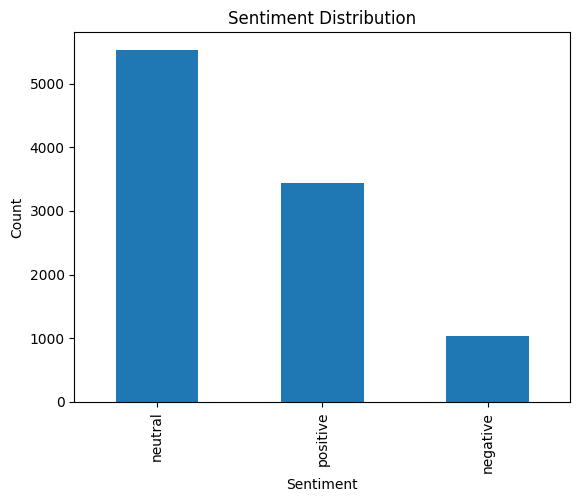

In [8]:
import matplotlib.pyplot as plt

df0['Sentiment'].value_counts().plot(kind='bar')
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()